# Pizza Place Sales Analysis

In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [70]:
pizza_types = pd.read_csv(r"C:\Users\USER\Downloads\Pizza-Place-Sales\pizza_sales\pizza_types.csv", encoding="latin-1")
pizzas = pd.read_csv(r"C:\Users\USER\Downloads\Pizza-Place-Sales\pizza_sales\pizzas.csv")
order_details = pd.read_csv(r"C:\Users\USER\Downloads\Pizza-Place-Sales\pizza_sales\order_details.csv")
orders = pd.read_csv(r"C:\Users\USER\Downloads\Pizza-Place-Sales\pizza_sales\orders.csv")

In [71]:
pizza_types.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   pizza_type_id  32 non-null     object
 1   name           32 non-null     object
 2   category       32 non-null     object
 3   ingredients    32 non-null     object
dtypes: object(4)
memory usage: 1.1+ KB


In [72]:
pizza_types.isna().sum()

pizza_type_id    0
name             0
category         0
ingredients      0
dtype: int64

In [73]:
pizzas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   pizza_id       96 non-null     object 
 1   pizza_type_id  96 non-null     object 
 2   size           96 non-null     object 
 3   price          96 non-null     float64
dtypes: float64(1), object(3)
memory usage: 3.1+ KB


In [74]:
pizza_types.shape

(32, 4)

In [75]:
pizzas.shape

(96, 4)

In [76]:
order_details.shape

(48620, 4)

In [77]:
orders.shape

(21350, 3)

Want to know all thier columns if they are thesame before merging them together

In [78]:
pizza_types.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   pizza_type_id  32 non-null     object
 1   name           32 non-null     object
 2   category       32 non-null     object
 3   ingredients    32 non-null     object
dtypes: object(4)
memory usage: 1.1+ KB


In [79]:
pizzas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   pizza_id       96 non-null     object 
 1   pizza_type_id  96 non-null     object 
 2   size           96 non-null     object 
 3   price          96 non-null     float64
dtypes: float64(1), object(3)
memory usage: 3.1+ KB


In [80]:
order_details.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48620 entries, 0 to 48619
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   order_details_id  48620 non-null  int64 
 1   order_id          48620 non-null  int64 
 2   pizza_id          48620 non-null  object
 3   quantity          48620 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB


In [81]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21350 entries, 0 to 21349
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   order_id  21350 non-null  int64 
 1   date      21350 non-null  object
 2   time      21350 non-null  object
dtypes: int64(1), object(2)
memory usage: 500.5+ KB


## Merge into a single dataframe


In [82]:
df1= pd.merge(order_details,orders, on="order_id", how="inner")
df1.head(10)

,order_details_id,order_id,pizza_id,quantity,date,time
0,1,1,hawaiian_m,1,2015-01-01,11:38:36
1,2,2,classic_dlx_m,1,2015-01-01,11:57:40
2,3,2,five_cheese_l,1,2015-01-01,11:57:40
3,4,2,ital_supr_l,1,2015-01-01,11:57:40
4,5,2,mexicana_m,1,2015-01-01,11:57:40
5,6,2,thai_ckn_l,1,2015-01-01,11:57:40
6,7,3,ital_supr_m,1,2015-01-01,12:12:28
7,8,3,prsc_argla_l,1,2015-01-01,12:12:28
8,9,4,ital_supr_m,1,2015-01-01,12:16:31
9,10,5,ital_supr_m,1,2015-01-01,12:21:30


In [83]:
df2 = pd.merge(df1,pizzas, on="pizza_id", how="inner")
df2.head(10)

,order_details_id,order_id,pizza_id,quantity,date,time,pizza_type_id,size,price
0,1,1,hawaiian_m,1,2015-01-01,11:38:36,hawaiian,M,13.25
1,2,2,classic_dlx_m,1,2015-01-01,11:57:40,classic_dlx,M,16.00
2,3,2,five_cheese_l,1,2015-01-01,11:57:40,five_cheese,L,18.50
3,4,2,ital_supr_l,1,2015-01-01,11:57:40,ital_supr,L,20.75
4,5,2,mexicana_m,1,2015-01-01,11:57:40,mexicana,M,16.00
5,6,2,thai_ckn_l,1,2015-01-01,11:57:40,thai_ckn,L,20.75
6,7,3,ital_supr_m,1,2015-01-01,12:12:28,ital_supr,M,16.50
7,8,3,prsc_argla_l,1,2015-01-01,12:12:28,prsc_argla,L,20.75
8,9,4,ital_supr_m,1,2015-01-01,12:16:31,ital_supr,M,16.50
9,10,5,ital_supr_m,1,2015-01-01,12:21:30,ital_supr,M,16.50


In [84]:
df2.tail()

,order_details_id,order_id,pizza_id,quantity,date,time,pizza_type_id,size,price
48615,48616,21348,ckn_alfredo_m,1,2015-12-31,21:23:10,ckn_alfredo,M,16.75
48616,48617,21348,four_cheese_l,1,2015-12-31,21:23:10,four_cheese,L,17.95
48617,48618,21348,napolitana_s,1,2015-12-31,21:23:10,napolitana,S,12.00
48618,48619,21349,mexicana_l,1,2015-12-31,22:09:54,mexicana,L,20.25
48619,48620,21350,bbq_ckn_s,1,2015-12-31,23:02:05,bbq_ckn,S,12.75


In [85]:
data = pd.merge(df2,pizza_types, on="pizza_type_id",how="inner")
data

,order_details_id,order_id,pizza_id,quantity,date,time,pizza_type_id,size,price,name,category,ingredients
0,1,1,hawaiian_m,1,2015-01-01,11:38:36,hawaiian,M,13.25,The Hawaiian Pizza,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese"
1,2,2,classic_dlx_m,1,2015-01-01,11:57:40,classic_dlx,M,16.00,The Classic Deluxe Pizza,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,..."
2,3,2,five_cheese_l,1,2015-01-01,11:57:40,five_cheese,L,18.50,The Five Cheese Pizza,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go..."
3,4,2,ital_supr_l,1,2015-01-01,11:57:40,ital_supr,L,20.75,The Italian Supreme Pizza,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni..."
4,5,2,mexicana_m,1,2015-01-01,11:57:40,mexicana,M,16.00,The Mexicana Pizza,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O..."
...,...,...,...,...,...,...,...,...,...,...,...,...
48615,48616,21348,ckn_alfredo_m,1,2015-12-31,21:23:10,ckn_alfredo,M,16.75,The Chicken Alfredo Pizza,Chicken,"Chicken, Red Onions, Red Peppers, Mushrooms, A..."
48616,48617,21348,four_cheese_l,1,2015-12-31,21:23:10,four_cheese,L,17.95,The Four Cheese Pizza,Veggie,"Ricotta Cheese, Gorgonzola Piccante Cheese, Mo..."
48617,48618,21348,napolitana_s,1,2015-12-31,21:23:10,napolitana,S,12.00,The Napolitana Pizza,Classic,"Tomatoes, Anchovies, Green Olives, Red Onions,..."
48618,48619,21349,mexicana_l,1,2015-12-31,22:09:54,mexicana,L,20.25,The Mexicana Pizza,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O..."


In [86]:
#setting our index as the order details id
data.set_index("order_details_id",inplace=True)
data.head()

,order_id,pizza_id,quantity,date,time,pizza_type_id,size,price,name,category,ingredients
order_details_id,,,,,,,,,,,
1,1,hawaiian_m,1,2015-01-01,11:38:36,hawaiian,M,13.25,The Hawaiian Pizza,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese"
2,2,classic_dlx_m,1,2015-01-01,11:57:40,classic_dlx,M,16.00,The Classic Deluxe Pizza,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,..."
3,2,five_cheese_l,1,2015-01-01,11:57:40,five_cheese,L,18.50,The Five Cheese Pizza,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go..."
4,2,ital_supr_l,1,2015-01-01,11:57:40,ital_supr,L,20.75,The Italian Supreme Pizza,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni..."
5,2,mexicana_m,1,2015-01-01,11:57:40,mexicana,M,16.00,The Mexicana Pizza,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O..."


In [87]:
#dropping the duplicate column
data.drop(columns=["pizza_type_id"], inplace=True)
data.head()

,order_id,pizza_id,quantity,date,time,size,price,name,category,ingredients
order_details_id,,,,,,,,,,
1,1,hawaiian_m,1,2015-01-01,11:38:36,M,13.25,The Hawaiian Pizza,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese"
2,2,classic_dlx_m,1,2015-01-01,11:57:40,M,16.00,The Classic Deluxe Pizza,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,..."
3,2,five_cheese_l,1,2015-01-01,11:57:40,L,18.50,The Five Cheese Pizza,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go..."
4,2,ital_supr_l,1,2015-01-01,11:57:40,L,20.75,The Italian Supreme Pizza,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni..."
5,2,mexicana_m,1,2015-01-01,11:57:40,M,16.00,The Mexicana Pizza,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O..."


In [88]:
data.shape

(48620, 10)

In [89]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 48620 entries, 1 to 48620
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   order_id     48620 non-null  int64  
 1   pizza_id     48620 non-null  object 
 2   quantity     48620 non-null  int64  
 3   date         48620 non-null  object 
 4   time         48620 non-null  object 
 5   size         48620 non-null  object 
 6   price        48620 non-null  float64
 7   name         48620 non-null  object 
 8   category     48620 non-null  object 
 9   ingredients  48620 non-null  object 
dtypes: float64(1), int64(2), object(7)
memory usage: 4.1+ MB


In [90]:
data.isna().sum()

order_id       0
pizza_id       0
quantity       0
date           0
time           0
size           0
price          0
name           0
category       0
ingredients    0
dtype: int64

## Parse date and time

`date` and `time` come in as plain text. Converting them properly lets us pull out the hour, the day
of the week, and the month.

In [91]:
#changing the date to date time data type
data["date"]= pd.to_datetime(data["date"])


In [92]:
#converting the time column to date time data type too
data["time"] = pd.to_datetime(data["time"], format="%H:%M:%S")

In [93]:
#extracting month name out of the date
data["Month"] = data["date"].dt.month_name()
data["Month_num"] = data["date"].dt.month

In [94]:
#extracting day of the week from the DateTime column
data["Day_of_Week"] = data["date"].dt.day_name()

In [95]:
#extracting hour 
data["Hour"] = data["time"].dt.hour

In [96]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 48620 entries, 1 to 48620
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_id     48620 non-null  int64         
 1   pizza_id     48620 non-null  object        
 2   quantity     48620 non-null  int64         
 3   date         48620 non-null  datetime64[ns]
 4   time         48620 non-null  datetime64[ns]
 5   size         48620 non-null  object        
 6   price        48620 non-null  float64       
 7   name         48620 non-null  object        
 8   category     48620 non-null  object        
 9   ingredients  48620 non-null  object        
 10  Month        48620 non-null  object        
 11  Month_num    48620 non-null  int32         
 12  Day_of_Week  48620 non-null  object        
 13  Hour         48620 non-null  int32         
dtypes: datetime64[ns](2), float64(1), int32(2), int64(2), object(7)
memory usage: 5.2+ MB


In [97]:
#checking and confirming the unique time durations
data["Hour"].unique()

array([11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 10,  9],
      dtype=int32)

### Order Value
We also add an `order_value` column (`quantity * price`), since that's the actual revenue
each line contributed.

In [98]:
#adding the column containing the order value of pizzas
data["Order_Value"] = data["quantity"]*data["price"]

In [99]:
data.head()

,order_id,pizza_id,quantity,date,time,size,price,name,category,ingredients,Month,Month_num,Day_of_Week,Hour,Order_Value
order_details_id,,,,,,,,,,,,,,,
1,1,hawaiian_m,1,2015-01-01,1900-01-01 11:38:36,M,13.25,The Hawaiian Pizza,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",January,1,Thursday,11,13.25
2,2,classic_dlx_m,1,2015-01-01,1900-01-01 11:57:40,M,16.00,The Classic Deluxe Pizza,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",January,1,Thursday,11,16.00
3,2,five_cheese_l,1,2015-01-01,1900-01-01 11:57:40,L,18.50,The Five Cheese Pizza,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",January,1,Thursday,11,18.50
4,2,ital_supr_l,1,2015-01-01,1900-01-01 11:57:40,L,20.75,The Italian Supreme Pizza,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",January,1,Thursday,11,20.75
5,2,mexicana_m,1,2015-01-01,1900-01-01 11:57:40,M,16.00,The Mexicana Pizza,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",January,1,Thursday,11,16.00


## 1. Headline numbers

Total revenue, total quantity sold, total orders, number of pizza types, and average pizza price.

In [100]:
total_revenue = data["Order_Value"].sum()
total_quantity = data["quantity"].sum()
total_orders = data["order_id"].nunique()
num_pizza_types = pizza_types.shape[0]
avg_pizza_price = pizzas["price"].mean()

print(f"Total revenue:        ${total_revenue:,.2f}")
print(f"Total quantity sold:  {total_quantity:,}")
print(f"Total orders:         {total_orders:,}")
print(f"Pizza types on menu:  {num_pizza_types}")
print(f"Average pizza price:  ${avg_pizza_price:.2f}")


Total revenue:        $817,860.05
Total quantity sold:  49,574
Total orders:         21,350
Pizza types on menu:  32
Average pizza price:  $16.44


**Insight:** the pizza place brought in roughly 817,860dollars   over the year from about 21,350 orders,
averaging just over 38dollars per order. Also 49,574 pizzas sold across 32 pizza types, at an average menu price
of $16.44.

## 2. Peak hours of sales

Grouping by `hour` and counting unique orders shows when the shop is busiest during the day.

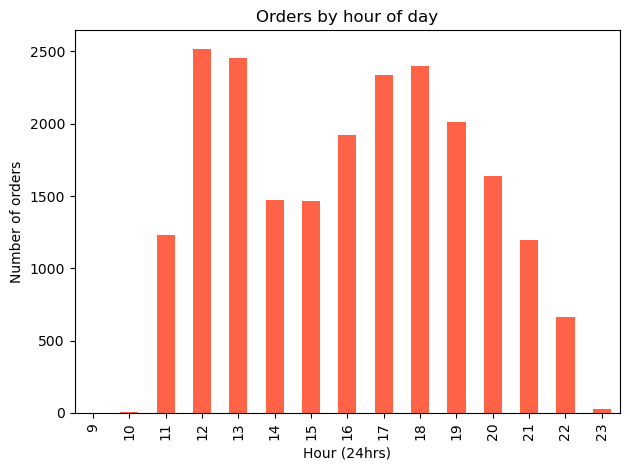

Busiest hour: 12 with 2520 orders


In [101]:
orders_by_hour = data.groupby("Hour")["order_id"].nunique().sort_index()
orders_by_hour
orders_by_hour.plot(kind="bar", color="tomato")
plt.title("Orders by hour of day")
plt.xlabel("Hour (24hrs)")
plt.ylabel("Number of orders")
plt.tight_layout()
plt.show()

print("Busiest hour:", orders_by_hour.idxmax(), "with", orders_by_hour.max(), "orders")

**Insight:** orders cluster around two peaks, lunchtime (roughly 12:00–13:00) and dinnertime
(roughly 17:00–18:00), which lines up with normal meal patterns rather than any surprising behavior.

## 3. Sales by day of week

This uses total revenue per day, then reorders the days so the chart reads Monday through Sunday
instead of alphabetically.

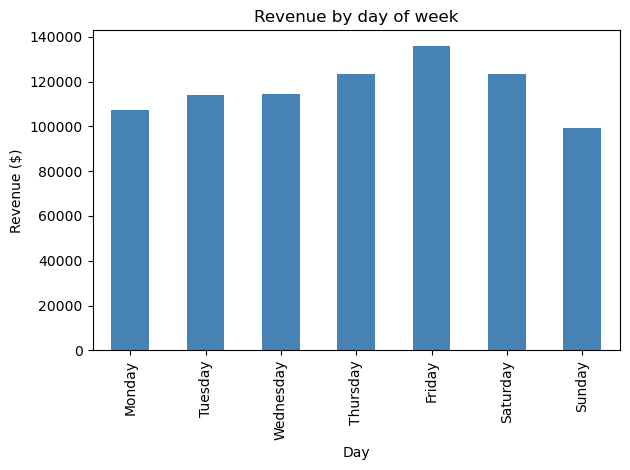

Best day: Friday ($136,073.90)
Slowest day: Sunday ($99,203.50)


In [102]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sales_by_day = data.groupby("Day_of_Week")["Order_Value"].sum().reindex(day_order)

sales_by_day.plot(kind="bar", color="steelblue")
plt.title("Revenue by day of week")
plt.xlabel("Day")
plt.ylabel("Revenue ($)")
plt.tight_layout()
plt.show()

print("Best day:", sales_by_day.idxmax(), f"(${sales_by_day.max():,.2f})")
print("Slowest day:", sales_by_day.idxmin(), f"(${sales_by_day.min():,.2f})")

**Insight:** Friday brings in the most revenue, with the weekend (Saturday) close behind, while
Sunday and Monday tend to be the slowest days. This is a common pattern for restaurants, people are
more likely to order out heading into or during the weekend.

## 4. Top 5 bestselling pizzas

"Bestselling" can mean two different things, either the most pizzas sold, or most revenue generated, so it's
worth looking at both, since they don't always agree.

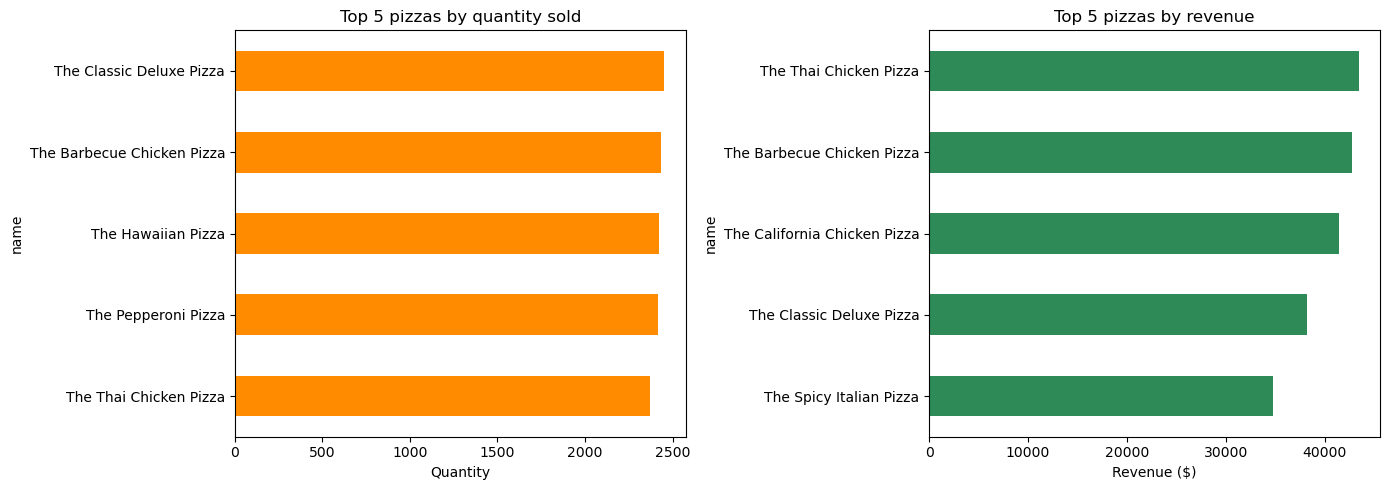

name
The Classic Deluxe Pizza      2453
The Barbecue Chicken Pizza    2432
The Hawaiian Pizza            2422
The Pepperoni Pizza           2418
The Thai Chicken Pizza        2371
Name: quantity, dtype: int64

name
The Thai Chicken Pizza          43434.25
The Barbecue Chicken Pizza      42768.00
The California Chicken Pizza    41409.50
The Classic Deluxe Pizza        38180.50
The Spicy Italian Pizza         34831.25
Name: Order_Value, dtype: float64


In [103]:
top5_by_quantity = data.groupby("name")["quantity"].sum().sort_values(ascending=False).head(5)
top5_by_revenue = data.groupby("name")["Order_Value"].sum().sort_values(ascending=False).head(5)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top5_by_quantity.sort_values().plot(kind="barh", ax=axes[0], color="darkorange")
axes[0].set_title("Top 5 pizzas by quantity sold")
axes[0].set_xlabel("Quantity")

top5_by_revenue.sort_values().plot(kind="barh", ax=axes[1], color="seagreen")
axes[1].set_title("Top 5 pizzas by revenue")
axes[1].set_xlabel("Revenue ($)")

plt.tight_layout()
plt.show()

print(top5_by_quantity)
print()
print(top5_by_revenue)

**Insight:** compare the two lists above, if a pizza appears on the quantity list but not the
revenue list, it's popular but cheap (probably sold mostly in the Small size); if it's the other way
around, it's a lower-volume but higher-priced item carrying its weight in revenue.

## 5. Monthly sales trend

Grouping revenue by month and plotting it as a line shows whether sales grow, shrink, or stay flat
across the year.

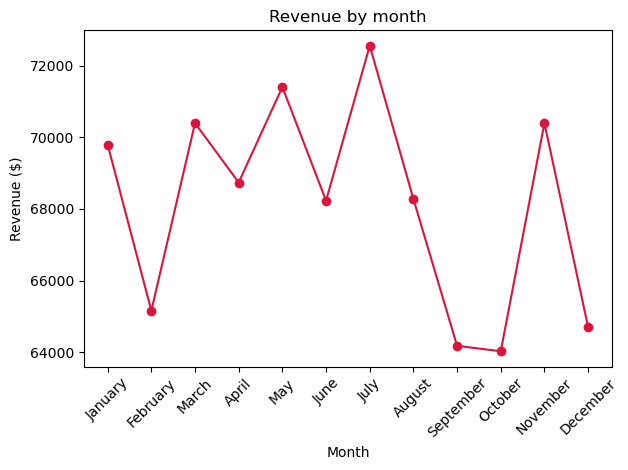

,Month,Order_Value
0,January,69793.30
1,February,65159.60
2,March,70397.10
3,April,68736.80
4,May,71402.75
5,June,68230.20
6,July,72557.90
7,August,68278.25
8,September,64180.05
9,October,64027.60


In [104]:
sales_by_month = data.groupby(["Month_num", "Month"])["Order_Value"].sum().reset_index()
sales_by_month = sales_by_month.sort_values("Month_num")

plt.plot(sales_by_month["Month"], sales_by_month["Order_Value"], marker="o", color="crimson")
plt.title("Revenue by month")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

sales_by_month[["Month", "Order_Value"]]

**Insight:** we can see that the revenue revenue reaches the point of the year in july (above $72,000) due to summer vacations and warm weather gatherings, sales drop sharply to the lowest point of the year in september and october as the back-to-school season kicks in. There sees a strong recovery in November as people shop more festival. 

## 6. Underperforming pizza types

The pizzas that sell the least, and those pizzas categories dragging behind the others

Lowest-selling pizzas by quantity:
name
The Brie Carre Pizza         490
The Mediterranean Pizza      934
The Calabrese Pizza          937
The Spinach Supreme Pizza    950
The Soppressata Pizza        961
Name: quantity, dtype: int64

Revenue by category:
category
Classic    220053.10
Supreme    208197.00
Chicken    195919.50
Veggie     193690.45
Name: Order_Value, dtype: float64


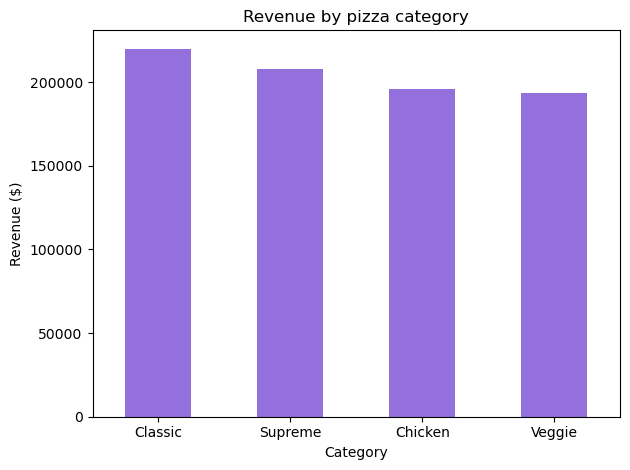

In [105]:
bottom5_by_quantity = data.groupby("name")["quantity"].sum().sort_values().head(5)
print("Lowest-selling pizzas by quantity:")
print(bottom5_by_quantity)

print()
revenue_by_category = data.groupby("category")["Order_Value"].sum().sort_values(ascending=False)
print("Revenue by category:")
print(revenue_by_category)

revenue_by_category.plot(kind="bar", color="mediumpurple")
plt.title("Revenue by pizza category")
plt.xlabel("Category")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Insight:** While Classic pizzas lead revenue and Veggies lads at the category level, individual data reveals Brie Carre Pizza is the worst-performing item on the menu, selling a low of only 490 units. Others item the Mediterranean,Calabrese, and Spanach Supreme pizzas also underperforms,failing to reach 1,000 units sold

## Summary

A short recap of what this notebook found, written in plain terms:

- **Total revenue:** about 817,860dollars across 21,350 orders in the year.
- **Volume:** 49,574 pizzas sold across 32 menu items, averaging $16.44 per pizza.
- **Timing:** lunch and dinner are the two daily peaks; Friday is the strongest day of the week.
- **Bestsellers vs revenue leaders:** the two "top 5" lists overlap but are not identical, some
  pizzas sell in volume, others earn more per sale.
- **Menu review candidates:** the bottom 5 pizzas by quantity, and any category trailing the rest,
  are the places worth a closer look.

From here, natural next steps would be looking at customer order size (pizzas per order), whether
certain pizza categories sell better at certain hours, or how the top sellers' revenue share has moved
month to month.